# Olist 브라질 전자상거래 데이터 분석 (수업 기법 버전)

수업에서 배운 pandas·시각화·정규표현식 기법을 단계별로 그대로 써서 분석하는 노트북이에요.

| 단계 | 수업 기법 | 하는 일 |
| --- | --- | --- |
| 0. 준비 | | 라이브러리, 한글 폰트, 데이터 불러오기 |
| 1. 정리 | 3장: to_datetime, drop_duplicates, assign, isna | 날짜 변환, 중복 리뷰 정리, 배송일·지연일 열 만들기 |
| 2. 합치기 | 4-1: merge, 행 수 확인 | 테이블 연결 |
| 3. 살펴보기 | 2장: describe, value_counts, nlargest | 기본 현황 |
| 4. 묶어서 비교 | 4장: groupby, cut, transform, pivot_table, crosstab, resample, rolling | 지연과 별점, 지역·시기 비교 |
| 5. 시각화 | 5·6장: line, heatmap, 비율 barh, violin, lmplot, lag plot | 결과를 그림으로 |
| 6. 텍스트 | regex: str.contains, str.extract | 포르투갈어 리뷰 분석 |
| 7. 정리 | | 발표용 질문 5개 |

**Colab에서 실행하는 법**
1. Kaggle에서 데이터를 받으면 `archive.zip` 파일이 생겨요.
2. Colab 왼쪽 폴더 아이콘을 눌러 `archive.zip`을 끌어다 놓거나, 아래 데이터 셀을 실행하면 나오는 업로드 버튼으로 올려요. 구글 드라이브의 `내 드라이브/archive.zip`에 두고 드라이브를 연결해도 돼요.
3. 메뉴에서 **런타임 → 모두 실행**.

## 0. 준비

In [1]:
import os, sys, glob, zipfile, re, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from pandas.plotting import lag_plot, autocorrelation_plot
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
IN_COLAB = 'google.colab' in sys.modules

In [2]:
# 한글 폰트 설정 (그래프 글자가 네모로 깨지지 않게)
if IN_COLAB:
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
def find_nanum():
    return [f for f in fm.findSystemFonts() + glob.glob(os.path.expanduser('~/.fonts/*.ttf'))
            if 'NanumGothic' in f and 'Bold' not in f and 'Coding' not in f]
font_files = find_nanum()
if not font_files:   # Colab이 아니거나 설치가 안 됐으면 구글 폰트 저장소에서 직접 받기
    try:
        import urllib.request
        os.makedirs(os.path.expanduser('~/.fonts'), exist_ok=True)
        urllib.request.urlretrieve('https://raw.githubusercontent.com/google/fonts/main/ofl/nanumgothic/NanumGothic-Regular.ttf',
                                   os.path.expanduser('~/.fonts/NanumGothic-Regular.ttf'))
        font_files = find_nanum()
    except Exception as e:
        print('폰트 다운로드 실패:', e)
if font_files:
    fm.fontManager.addfont(font_files[0])
    plt.rc('font', family=fm.FontProperties(fname=font_files[0]).get_name())
    print('한글 폰트:', fm.FontProperties(fname=font_files[0]).get_name())
else:
    print('한글 폰트를 찾지 못했어요. 그래프의 한글이 깨질 수 있어요.')
plt.rc('axes', unicode_minus=False)   # 마이너스 기호 깨짐 방지
sns.set_style('whitegrid', {'font.family': plt.rcParams['font.family']})

한글 폰트: NanumGothic


In [3]:
# 데이터 불러오기: archive.zip을 찾아서 olist_data 폴더에 풀기
DATA_DIR = 'olist_data'
if not os.path.exists(f'{DATA_DIR}/olist_orders_dataset.csv'):
    candidates = ['archive.zip', '/content/archive.zip', '/content/drive/MyDrive/archive.zip']
    if IN_COLAB and not any(os.path.exists(p) for p in candidates):
        try:
            from google.colab import drive
            drive.mount('/content/drive')          # 드라이브에 archive.zip을 둔 경우
        except Exception as e:
            print('드라이브 연결 건너뜀:', e)
    zip_path = next((p for p in candidates if os.path.exists(p)), None)
    if zip_path is None and IN_COLAB:
        from google.colab import files
        print('archive.zip 파일을 선택해서 올려주세요')
        zip_path = list(files.upload())[0]
    zipfile.ZipFile(zip_path).extractall(DATA_DIR)
sorted(os.listdir(DATA_DIR))

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

## 1단계. 데이터 정리 (3장)

테이블 9개의 관계는 이래요. 주문(orders)이 중심이고, 나머지가 `order_id`, `customer_id`, `product_id`, `seller_id`로 이어져요.

```
customers ─ customer_id ─ orders ─ order_id ─┬─ order_items ─┬─ product_id ─ products ─ category_translation
                                             │               └─ seller_id ─ sellers
                                             ├─ order_payments
                                             └─ order_reviews
```

In [4]:
def read(name, **kw):
    return pd.read_csv(f'{DATA_DIR}/olist_{name}_dataset.csv', **kw)

date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
orders = read('orders', parse_dates=date_cols)          # parse_dates: 읽으면서 날짜 타입으로 (3장 to_datetime)
customers = read('customers')
items = read('order_items')
products = read('products')
sellers = read('sellers')
payments = read('order_payments')
reviews_raw = read('order_reviews')
geo = read('geolocation')
cat_tr = pd.read_csv(f'{DATA_DIR}/product_category_name_translation.csv')

# 테이블별 크기 확인 (2장 shape)
pd.DataFrame({name: t.shape for name, t in [('orders', orders), ('customers', customers), ('items', items),
              ('products', products), ('sellers', sellers), ('payments', payments), ('reviews', reviews_raw),
              ('geolocation', geo)]}, index=['rows', 'cols']).T

,rows,cols
orders,99441,8
customers,99441,5
items,112650,7
products,32951,9
sellers,3095,4
payments,103886,5
reviews,99224,7
geolocation,1000163,5


In [5]:
# 결측 확인 (3장 isna): 날짜 열에 빈칸이 있는 건 아직 배송 안 됐거나 취소된 주문
print(orders.isna().sum())
print()
print(orders.order_status.value_counts())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
# 중복 확인 (3장 duplicated): 한 주문에 리뷰가 여러 개인 경우
dup_orders = reviews_raw.order_id.duplicated(keep=False)
print('리뷰 행:', len(reviews_raw), '| 리뷰가 2개 이상인 주문의 행:', dup_orders.sum())

# 정렬 후 drop_duplicates: 가장 마지막에 답한 리뷰 하나만 남김 (3장 중복 제거 패턴)
reviews = (reviews_raw.sort_values('review_answer_timestamp')
                      .drop_duplicates('order_id', keep='last'))
print('정리 후 리뷰:', len(reviews))

리뷰 행: 99224 | 리뷰가 2개 이상인 주문의 행: 1098
정리 후 리뷰: 98673


In [7]:
# 새 열 만들기 (3장 assign + lambda)
orders = orders.assign(
    days=lambda x: (x.order_delivered_customer_date - x.order_purchase_timestamp).dt.days,        # 실제 배송일
    promised_days=lambda x: (x.order_estimated_delivery_date - x.order_purchase_timestamp).dt.days,  # 약속한 배송일
    delay=lambda x: (x.order_delivered_customer_date - x.order_estimated_delivery_date).dt.days,  # 약속 대비 지연 (음수면 일찍)
    late=lambda x: x.delay > 0,                                                                   # 약속보다 늦었나
    weekday=lambda x: x.order_purchase_timestamp.dt.dayofweek,                                    # 0=월 ~ 6=일
    hour=lambda x: x.order_purchase_timestamp.dt.hour,
    month=lambda x: x.order_purchase_timestamp.dt.to_period('M'),
)
orders[['order_purchase_timestamp', 'days', 'promised_days', 'delay', 'late']].head()

,order_purchase_timestamp,days,promised_days,delay,late
0,2017-10-02 10:56:33,8.0,15,-8.0,False
1,2018-07-24 20:41:37,13.0,19,-6.0,False
2,2018-08-08 08:38:49,9.0,26,-18.0,False
3,2017-11-18 19:28:06,13.0,26,-13.0,False
4,2018-02-13 21:18:39,2.0,12,-10.0,False


## 2단계. 합치기 (4-1 merge)

merge할 때마다 **행 수가 어떻게 바뀌는지** 확인하는 게 핵심이에요 (시험에도 나왔던 부분).

In [8]:
# 주문 단위 표: 주문 + 고객 + 리뷰
df = (orders.merge(customers, on='customer_id', how='left')
            .merge(reviews[['order_id', 'review_score', 'review_comment_title', 'review_comment_message',
                            'review_creation_date', 'review_answer_timestamp']], on='order_id', how='left'))
print('orders:', len(orders), '→ 고객·리뷰 붙인 뒤:', len(df), '(같아야 정상)')

# 상품을 붙이면? 주문 하나에 상품이 여러 개라 행이 늘어남
print('orders + items:', len(orders.merge(items, on='order_id')))
# inner vs left: 상품 정보가 없는 주문은 inner에서 사라짐
print('상품 정보가 없는 주문:', (~orders.order_id.isin(items.order_id)).sum())

orders: 99441 → 고객·리뷰 붙인 뒤: 99441 (같아야 정상)


orders + items: 112650


상품 정보가 없는 주문: 775


In [9]:
# 상품 단위 표: 상품 + 카테고리(영어) + 판매자 + 주문 정보
products = products.merge(cat_tr, on='product_category_name', how='left')
products['category'] = products.product_category_name_english.fillna('unknown')
item_df = (items.merge(products[['product_id', 'category', 'product_weight_g']], on='product_id', how='left')
                .merge(sellers, on='seller_id', how='left')
                .merge(df[['order_id', 'order_purchase_timestamp', 'customer_state', 'customer_zip_code_prefix',
                           'order_status', 'days', 'delay', 'late', 'review_score']], on='order_id', how='left'))
print('item_df:', item_df.shape)
item_df.head(3)

item_df: (112650, 20)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,category,product_weight_g,seller_zip_code_prefix,seller_city,seller_state,order_purchase_timestamp,customer_state,customer_zip_code_prefix,order_status,days,delay,late,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,cool_stuff,650.0,27277,volta redonda,SP,2017-09-13 08:59:02,RJ,28013,delivered,7.0,-9.0,False,5.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,pet_shop,30000.0,3471,sao paulo,SP,2017-04-26 10:53:06,SP,15775,delivered,16.0,-3.0,False,4.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,furniture_decor,3050.0,37564,borda da mata,MG,2018-01-14 14:33:31,MG,35661,delivered,7.0,-14.0,False,5.0


In [10]:
# 판매자-고객 거리(km): 우편번호 앞자리별 평균 위경도로 계산
zip_geo = geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()
item_df = (item_df.join(zip_geo, on='customer_zip_code_prefix').rename(columns={'geolocation_lat': 'c_lat', 'geolocation_lng': 'c_lng'})
                  .join(zip_geo, on='seller_zip_code_prefix').rename(columns={'geolocation_lat': 's_lat', 'geolocation_lng': 's_lng'}))
lat1, lng1, lat2, lng2 = [np.radians(item_df[c]) for c in ['s_lat', 's_lng', 'c_lat', 'c_lng']]
item_df['dist_km'] = 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2))

# 브라질 5개 권역 (주 → 권역)
REGION = {**{s: '북부' for s in ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO']},
          **{s: '북동부' for s in ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE']},
          **{s: '중서부' for s in ['DF', 'GO', 'MT', 'MS']},
          **{s: '남동부' for s in ['ES', 'MG', 'RJ', 'SP']},
          **{s: '남부' for s in ['PR', 'RS', 'SC']}}
df['region'] = df.customer_state.map(REGION)
item_df['region'] = item_df.customer_state.map(REGION)
item_df[['seller_state', 'customer_state', 'dist_km', 'freight_value']].describe().round(1)

,dist_km,freight_value
count,112096.0,112650.0
mean,597.0,20.0
std,590.0,15.8
min,0.0,0.0
25%,184.1,13.1
50%,431.6,16.3
75%,792.3,21.2
max,8677.9,409.7


## 3단계. 살펴보기 (2장)

**분석 기간: 2017-01-01 ~ 2018-08-15**
- 원본은 2016년 9월 ~ 2018년 10월이지만 2016년과 2018년 9~10월은 주문이 거의 없어요.
- 8월 하순은 데이터 수집이 끊겨 주문이 다 들어오지 않았어요 (하루 250건 → 8/29 14건). 그래서 **8/15까지 구매한 주문**만 써요.
- 8/15까지 산 주문의 배송·리뷰 결과는 8/15 뒤에 나왔어도 그대로 써요. 늦게 오는 주문일수록 늦게 기록되니까, 빼면 결과가 좋아 보이는 착시가 생겨요.

In [11]:
# 월별 주문 수: 앞뒤 몇 달은 거의 없고, 2018년 8월 하순부터 수집이 끊김
print(df.month.value_counts().sort_index().to_string())
daily_all = df.set_index('order_purchase_timestamp').resample('D').size()
print('\n' + '2018년 8월 15일 이후 하루 주문:', {d.strftime('%m/%d'): int(v) for d, v in daily_all['2018-08-15':'2018-08-31'].items()})

month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M



2018년 8월 15일 이후 하루 주문: {'08/15': 288, '08/16': 320, '08/17': 257, '08/18': 198, '08/19': 204, '08/20': 256, '08/21': 243, '08/22': 187, '08/23': 144, '08/24': 99, '08/25': 69, '08/26': 73, '08/27': 67, '08/28': 44, '08/29': 14, '08/30': 4, '08/31': 1}


In [12]:
# 분석 기간 (2017-01-01 ~ 2018-08-15에 구매한 주문)
PERIOD_START, PERIOD_END = pd.Timestamp('2017-01-01'), pd.Timestamp('2018-08-15')
in_period = (df.order_purchase_timestamp >= PERIOD_START) & (df.order_purchase_timestamp < PERIOD_END + pd.Timedelta(days=1))
dp = df[in_period].copy()                                                            # 기간 안 모든 주문 (요일·시간, 재구매 등)
dd = dp[(dp.order_status == 'delivered') & dp.order_delivered_customer_date.notna()].copy()   # 그중 배송 완료 (배송·리뷰 분석)
item_df = item_df[item_df.order_id.isin(dp.order_id)]                               # 상품 표도 같은 기간으로
print('분석 대상 주문:', len(dd))
dd[['days', 'promised_days', 'delay', 'review_score']].describe().round(2)

분석 대상 주문: 94071


,days,promised_days,delay,review_score
count,94071.00,94071.00,94071.00,93436.00
mean,12.22,23.49,-11.87,4.15
std,9.59,8.48,10.12,1.29
min,0.00,2.00,-147.00,1.00
25%,6.00,18.00,-17.00,4.00
50%,10.00,23.00,-13.00,5.00
75%,15.00,28.00,-7.00,5.00
max,209.00,155.00,188.00,5.00


In [13]:
print('약속보다 늦게 온 비율:', round(dd.late.mean(), 3))
print('실제 배송일 중앙값:', dd.days.median(), '일 | 약속한 배송일 중앙값:', dd.promised_days.median(), '일')
print()
print('별점 분포 (비율):', dd.review_score.value_counts(normalize=True).sort_index().round(3).to_dict())

약속보다 늦게 온 비율: 0.069
실제 배송일 중앙값: 10.0 일 | 약속한 배송일 중앙값: 23.0 일

별점 분포 (비율): {1.0: 0.098, 2.0: 0.031, 3.0: 0.083, 4.0: 0.197, 5.0: 0.59}


In [14]:
# 매출 상위 카테고리 (groupby + nlargest)
item_df.groupby('category').price.sum().nlargest(10).round(0)

category
health_beauty            1212859.0
watches_gifts            1183968.0
bed_bath_table           1015946.0
sports_leisure            970050.0
computers_accessories     900592.0
furniture_decor           713536.0
cool_stuff                630052.0
housewares                612481.0
auto                      574767.0
garden_tools              479935.0
Name: price, dtype: float64

In [15]:
# 요일·시간 (value_counts) / 재구매 고객 (customer_unique_id 기준!)
WEEKDAY = ['월', '화', '수', '목', '금', '토', '일']
print('요일별 주문:', dp.weekday.map(dict(enumerate(WEEKDAY))).value_counts().to_dict())
print('주문 많은 시간 TOP 4:', dp.hour.value_counts().head(4).to_dict())
per_customer = dp.groupby('customer_unique_id').order_id.nunique()
print('재구매 고객 비율:', round((per_customer > 1).mean(), 3))

요일별 주문: {'월': 15818, '화': 15609, '수': 15300, '목': 14236, '금': 13718, '일': 11655, '토': 10576}
주문 많은 시간 TOP 4: {16: 6524, 14: 6410, 11: 6397, 13: 6356}
재구매 고객 비율: 0.031


## 4단계. 묶어서 비교 (4장)

### 4-1. 지연 구간별 별점 (cut + groupby)

In [16]:
dd['delay_bin'] = pd.cut(dd.delay, [-100, -1, 0, 1, 3, 5, 100],
                         labels=['일찍 옴', '당일', '1일 늦음', '2~3일 늦음', '4~5일 늦음', '6일+ 늦음'])
delay_table = dd.groupby('delay_bin').agg(
    orders=('order_id', 'size'),
    mean_score=('review_score', 'mean'),
    low_rate=('review_score', lambda s: (s <= 2).mean()),   # 1~2점 비율
)
delay_table.round(3)

,orders,mean_score,low_rate
delay_bin,,,
일찍 옴,86377,4.291,0.092
당일,1202,4.011,0.127
1일 늦음,808,3.716,0.199
2~3일 늦음,1031,2.928,0.420
4~5일 늦음,894,2.344,0.584
6일+ 늦음,3715,1.721,0.766


**해석**: 하루만 늦어도 별점이 떨어지고, 2~3일 늦으면 급락해요. 6일 이상이면 1점대 후반에서 바닥이에요.

### 4-2. 같은 배송일인데 약속을 지켰을 때 vs 어겼을 때 (pivot_table)
"오래 걸려서" 화난 걸까, "약속을 어겨서" 화난 걸까?

In [17]:
dd['days_bin'] = pd.cut(dd.days, [5, 10, 15, 20, 30, 60], labels=['5~10일', '10~15일', '15~20일', '20~30일', '30~60일'])
same_days = dd.pivot_table(index='days_bin', columns='late', values='review_score', aggfunc='mean')
same_days.columns = ['약속 지킴', '약속 어김']
same_days.round(2)

,약속 지킴,약속 어김
days_bin,,
5~10일,4.35,3.52
10~15일,4.26,3.08
15~20일,4.14,2.89
20~30일,3.96,2.54
30~60일,3.59,1.82


**해석**: 똑같이 15~20일이 걸려도 약속을 지키면 4점대, 어기면 3점 아래예요. 고객은 **절대 일수보다 약속 대비**에 반응해요.

### 4-3. 자기 지역 평균보다 느린 주문 (transform)
수업의 "4월 비가 이틀에 몰렸다" 예제처럼, 그룹 값을 원래 행에 붙여서 비교해요.

In [18]:
dd['region_avg_days'] = dd.groupby('region').days.transform('mean')       # 행 수 유지
dd['slower_than_region'] = dd.days > dd.region_avg_days
dd.groupby('slower_than_region').review_score.mean().round(2)

slower_than_region
False    4.36
True     3.79
Name: review_score, dtype: float64

### 4-4. 지역 × 월 지연율 (pivot_table) / 지역별 별점 분포 (crosstab)

In [19]:
region_month = dd.pivot_table(index='region', columns='month', values='late', aggfunc='mean')
region_month.round(2)

month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
region,,,,,,,,,,,,,,,,,,,,
남동부,0.02,0.03,0.03,0.06,0.03,0.03,0.02,0.02,0.03,0.04,0.11,0.07,0.05,0.13,0.17,0.03,0.06,0.01,0.03,0.10
남부,0.03,0.03,0.07,0.04,0.02,0.01,0.02,0.04,0.03,0.03,0.12,0.07,0.06,0.15,0.17,0.02,0.05,0.00,0.02,0.04
북동부,0.06,0.06,0.13,0.14,0.02,0.06,0.09,0.06,0.13,0.10,0.22,0.10,0.09,0.22,0.33,0.19,0.15,0.05,0.06,0.02
북부,0.00,0.00,0.11,0.04,0.02,0.03,0.05,0.00,0.07,0.04,0.12,0.04,0.05,0.17,0.37,0.20,0.10,0.00,0.03,0.03
중서부,0.05,0.01,0.03,0.05,0.02,0.03,0.01,0.01,0.05,0.03,0.12,0.07,0.04,0.14,0.23,0.03,0.07,0.01,0.04,0.07


In [20]:
# 월별 전체 지연율: 2018년 2~3월이 튐
monthly_late = dd.groupby('month').late.mean()
monthly_late.round(3).to_frame('late_rate').T

month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
late_rate,0.029,0.03,0.046,0.066,0.03,0.03,0.028,0.029,0.044,0.042,0.124,0.075,0.057,0.141,0.19,0.045,0.066,0.012,0.034,0.083


In [21]:
state_score = pd.crosstab(dd.customer_state, dd.review_score, normalize='index')   # 행 합 = 1
state_score['low(1~2점)'] = state_score[1] + state_score[2]
state_score.sort_values('low(1~2점)', ascending=False).head(8).round(3)

review_score,1.0,2.0,3.0,4.0,5.0,low(1~2점)
customer_state,,,,,,
AL,0.153,0.061,0.071,0.216,0.499,0.214
MA,0.159,0.042,0.099,0.215,0.484,0.201
SE,0.155,0.036,0.088,0.195,0.526,0.191
RJ,0.149,0.036,0.083,0.173,0.559,0.185
PA,0.143,0.036,0.098,0.208,0.515,0.179
CE,0.137,0.037,0.102,0.206,0.520,0.173
BA,0.133,0.038,0.101,0.223,0.504,0.172
PI,0.128,0.032,0.088,0.218,0.533,0.161


### 4-5. 일별 주문과 블랙프라이데이 (resample + rolling)

In [22]:
daily = dd.set_index('order_purchase_timestamp').resample('D').size()
roll7 = daily.rolling(7).mean()                 # 7일 이동평균
print('주문이 가장 많은 날:', daily.idxmax().date(), daily.max(), '건 | 하루 중앙값:', daily.median())
bf = dd[(dd.order_purchase_timestamp >= '2017-11-24') & (dd.order_purchase_timestamp < '2017-11-25')]
print('블랙프라이데이(2017-11-24) 주문의 지연율:', round(bf.late.mean(), 3), '| 전체 평균:', round(dd.late.mean(), 3))

주문이 가장 많은 날: 2017-11-24 1147 건 | 하루 중앙값: 148.0
블랙프라이데이(2017-11-24) 주문의 지연율: 0.173 | 전체 평균: 0.069


## 5단계. 시각화 (5·6장)

### 5-1. 일별 주문 + 7일 이동평균 (line)

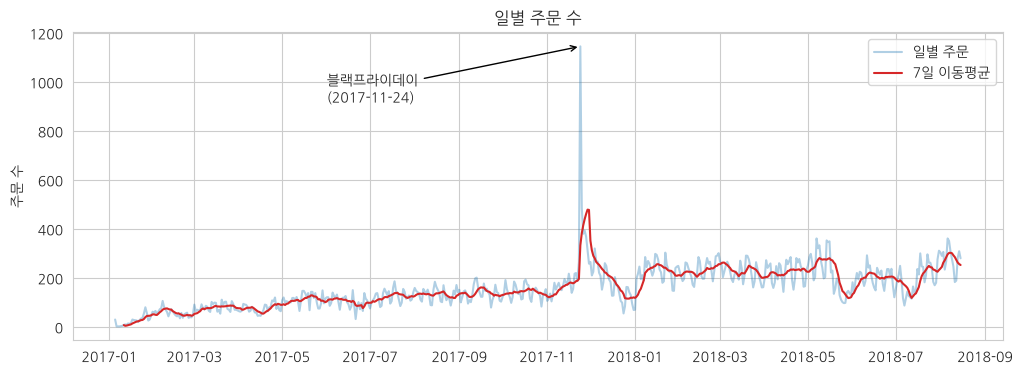

In [23]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, alpha=0.35, label='일별 주문')          # matplotlib으로 직접 (날짜 축에 주석 달기 쉬움)
ax.plot(roll7.index, roll7.values, color='tab:red', label='7일 이동평균')
import matplotlib.dates as mdates   # 날짜를 숫자로 바꿔 줘야 화살표가 그려짐
ax.annotate('블랙프라이데이\n(2017-11-24)', xy=(mdates.date2num(daily.idxmax()), daily.max()),
            xytext=(mdates.date2num(pd.Timestamp('2017-06-01')), daily.max() * 0.8), arrowprops={'arrowstyle': '->', 'color': 'k'})
ax.set_title('일별 주문 수'); ax.set_xlabel(''); ax.set_ylabel('주문 수'); ax.legend()
plt.show()

### 5-2. 언제 쇼핑할까? 요일 × 시간 히트맵 (crosstab + heatmap)

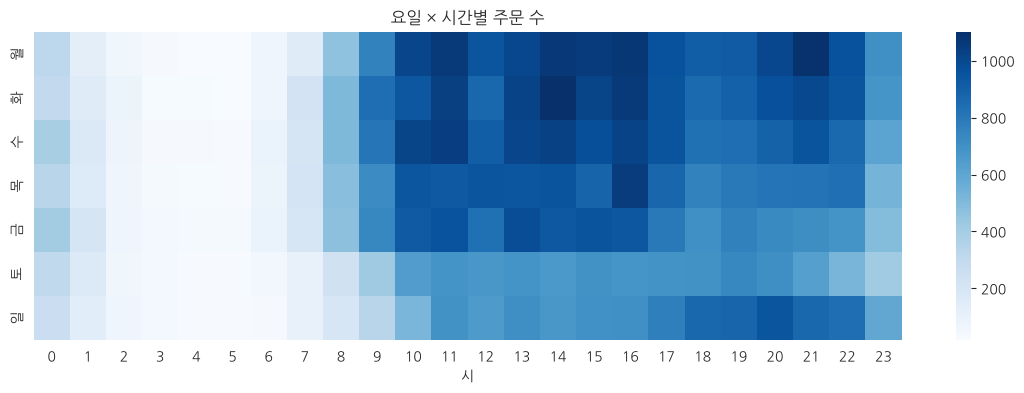

가장 많은 칸: ('화', np.int32(14)) 1101 건


In [24]:
weekday_hour = pd.crosstab(dp.weekday.map(dict(enumerate(WEEKDAY))), dp.hour).reindex(WEEKDAY)   # 기간 안 주문만
plt.figure(figsize=(14, 4))
sns.heatmap(weekday_hour, cmap='Blues')
plt.title('요일 × 시간별 주문 수'); plt.xlabel('시'); plt.ylabel('')
plt.show()
print('가장 많은 칸:', weekday_hour.stack().idxmax(), weekday_hour.stack().max(), '건')

### 5-3. 지연 구간별 별점 (bar + 비율로 쌓은 bar)
별점은 1~5 정수라 바이올린을 그리면 모양이 뾰족하게 깨져요. 이런 데이터는 **별점 구성비를 100%로 쌓은 막대**(5장 normalized stacked bar)가 더 잘 보여요.

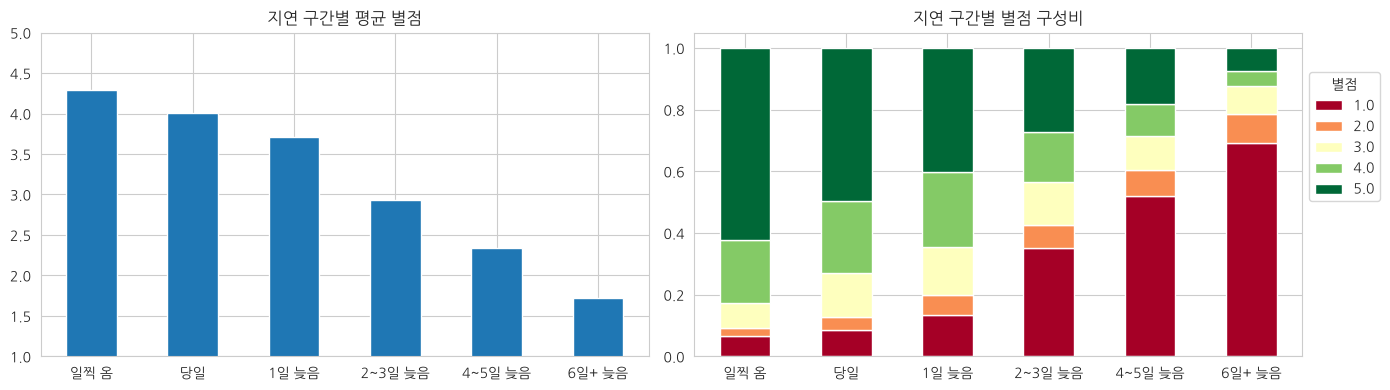

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
delay_table.mean_score.plot(kind='bar', ax=axes[0], color='tab:blue', rot=0)
axes[0].set_title('지연 구간별 평균 별점'); axes[0].set_ylim(1, 5); axes[0].set_xlabel('')
composition = pd.crosstab(dd.delay_bin, dd.review_score, normalize='index')     # 행 합 = 1
composition.plot(kind='bar', stacked=True, ax=axes[1], rot=0, colormap='RdYlGn')
axes[1].set_title('지연 구간별 별점 구성비'); axes[1].set_xlabel(''); axes[1].legend(title='별점', bbox_to_anchor=(1, 0.9))
plt.tight_layout(); plt.show()

### 5-4. 같은 배송일, 약속 지킴 vs 어김 (grouped bar)

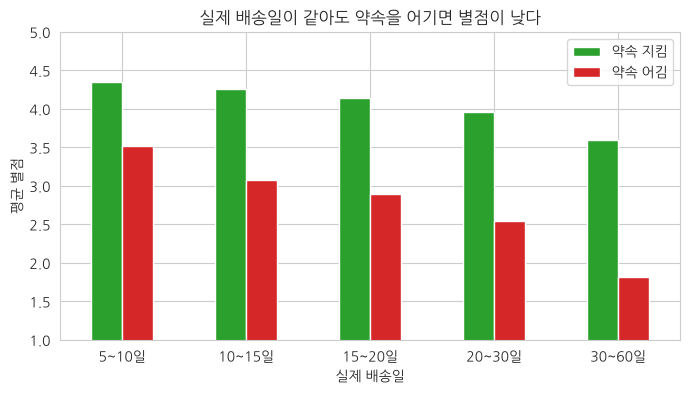

In [26]:
same_days.plot(kind='bar', rot=0, figsize=(8, 4), color=['tab:green', 'tab:red'])
plt.title('실제 배송일이 같아도 약속을 어기면 별점이 낮다'); plt.ylabel('평균 별점'); plt.xlabel('실제 배송일'); plt.ylim(1, 5)
plt.show()

### 5-5. 어느 주가 가장 불만이 많을까? (쓰나미 비율 barh 재현)
5장의 "쓰나미 비율" 그래프와 같은 방법이에요: 행 합을 1로 만든 비율표 → 정렬 → 상위 10개를 뒤집어서(1등이 맨 위) 쌓은 가로 막대.

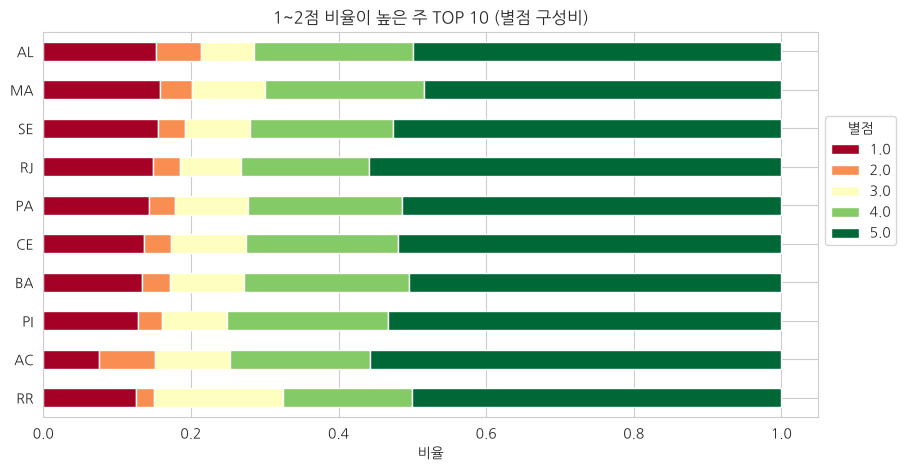

In [27]:
score_cols = [1, 2, 3, 4, 5]
top10 = state_score.sort_values('low(1~2점)', ascending=False)[score_cols].iloc[9::-1]   # 상위 10개 뒤집기
ax = top10.plot.barh(stacked=True, figsize=(10, 5), colormap='RdYlGn')
ax.set_title('1~2점 비율이 높은 주 TOP 10 (별점 구성비)'); ax.set_xlabel('비율'); ax.set_ylabel('')
ax.legend(title='별점', bbox_to_anchor=(1, 0.8))
plt.show()

### 5-6. 권역별 배송일 (boxplot)

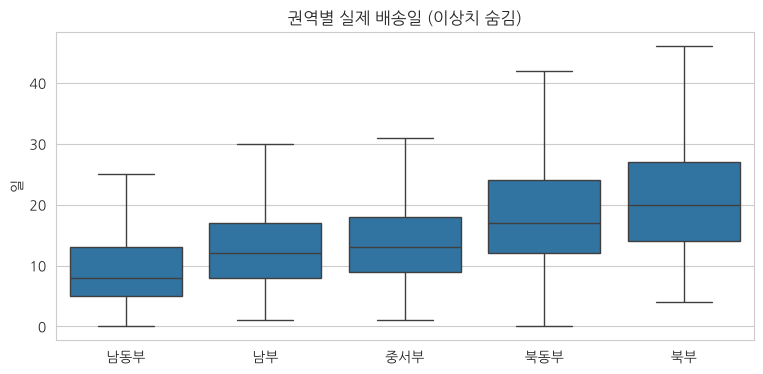

,median_days,late_rate,score
region,,,
남동부,8.0,0.062,4.174
남부,12.0,0.060,4.185
중서부,13.0,0.066,4.124
북동부,17.0,0.128,3.964
북부,20.0,0.086,4.030


In [28]:
order_region = ['남동부', '남부', '중서부', '북동부', '북부']
plt.figure(figsize=(9, 4))
sns.boxplot(data=dd, x='region', y='days', order=order_region, showfliers=False)
plt.title('권역별 실제 배송일 (이상치 숨김)'); plt.xlabel(''); plt.ylabel('일')
plt.show()
dd.groupby('region').agg(median_days=('days', 'median'), late_rate=('late', 'mean'), score=('review_score', 'mean')).reindex(order_region).round(3)

### 5-7. 거리와 운송비 (lmplot, col로 권역 나누기)
점이 10만 개라 5,000개만 뽑아서 그려요 (sample).

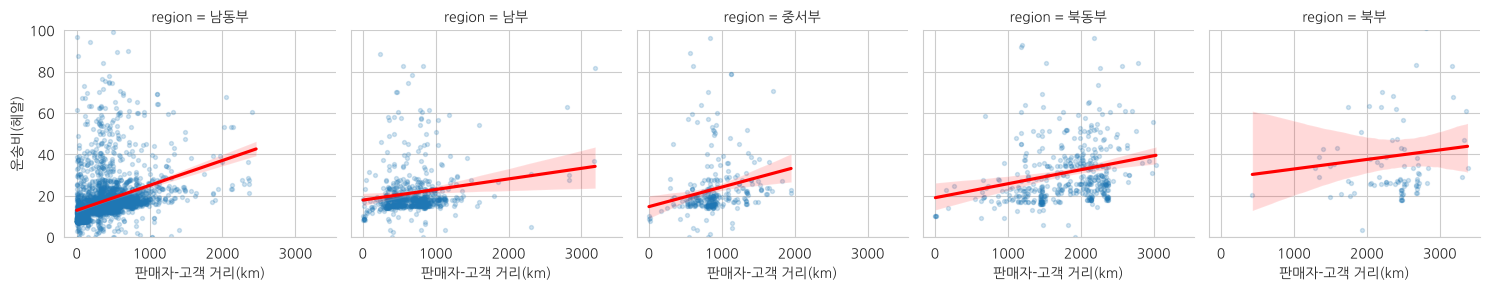

In [29]:
sample = item_df.dropna(subset=['dist_km', 'region']).sample(5000, random_state=0)
g = sns.lmplot(data=sample, x='dist_km', y='freight_value', col='region', col_order=order_region,
               height=3, scatter_kws={'alpha': 0.2, 's': 8}, line_kws={'color': 'red'})
g.set(ylim=(0, 100))
g.set_axis_labels('판매자-고객 거리(km)', '운송비(헤알)')
plt.show()

### 5-8. 요일 패턴 (lag plot, autocorrelation)
5-3장의 lag plot: 오늘 주문과 n일 뒤 주문의 관계. 7일 차이에서도 대각선에 몰리면 "요일 패턴"이 있다는 뜻이에요.

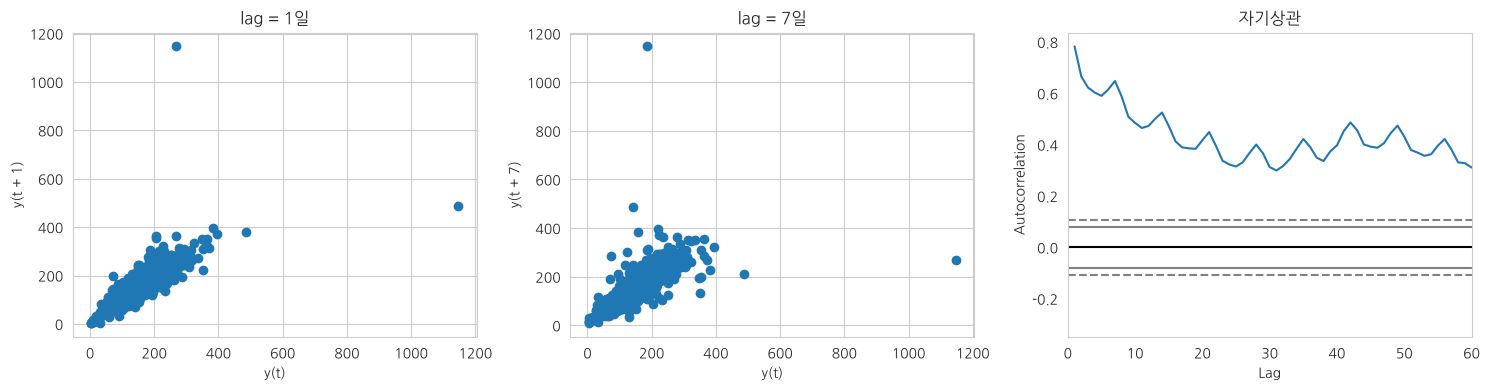

자기상관 lag1: 0.785 | lag7: 0.666


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lag_plot(daily, lag=1, ax=axes[0]); axes[0].set_title('lag = 1일')
lag_plot(daily, lag=7, ax=axes[1]); axes[1].set_title('lag = 7일')
autocorrelation_plot(daily, ax=axes[2]); axes[2].set_xlim(0, 60); axes[2].set_title('자기상관')
plt.tight_layout(); plt.show()
print('자기상관 lag1:', round(daily.autocorr(1), 3), '| lag7:', round(daily.autocorr(7), 3))

## 6단계. 텍스트 분석 (regex)

리뷰 글은 포르투갈어예요. 자주 나오는 표현:
- `não recebi` = 못 받았다, `atraso` = 지연, `prazo` = 기한, `errado` = 잘못된, `defeito` = 불량, `quebrado` = 깨진, `faltando` = 빠진
- `dias` = 일(날), `recomendo` = 추천해요

In [31]:
txt = dd.dropna(subset=['review_comment_message']).copy()
txt['msg'] = txt.review_comment_message.str.lower()
print('글이 있는 리뷰 비율:', round(dd.review_comment_message.notna().mean(), 3))
print('1~2점 리뷰 중 글 있는 비율:', round(dd[dd.review_score <= 2].review_comment_message.notna().mean(), 3))

글이 있는 리뷰 비율: 0.403
1~2점 리뷰 중 글 있는 비율: 0.752


In [32]:
# 불만 유형별 비율 (1~2점 리뷰, str.contains + 정규표현식)
COMPLAINTS = {
    '못 받음': r'n[aã]o\s+(?:recebi|chegou)|ainda n[aã]o|nunca chegou',
    '지연': r'atras|prazo|demor',
    '다른 상품': r'errad|diferente|veio outro',
    '불량·파손': r'quebrad|defeit|danific|n[aã]o funciona',
    '일부만 옴': r'faltando|falta|apenas um|s[oó] (?:um|uma|1)\b|incomplet',
}
low = txt[txt.review_score <= 2]
complaint_share = pd.DataFrame({
    '약속 어긴 주문': {k: low[low.late].msg.str.contains(p).mean() for k, p in COMPLAINTS.items()},
    '약속 지킨 주문': {k: low[~low.late].msg.str.contains(p).mean() for k, p in COMPLAINTS.items()},
})
complaint_share.round(3)

,약속 어긴 주문,약속 지킨 주문
못 받음,0.459,0.120
지연,0.255,0.083
다른 상품,0.012,0.101
불량·파손,0.008,0.084
일부만 옴,0.034,0.099


**해석**: 늦은 주문의 불만은 대부분 "못 받음·지연"이고, 제때 온 주문의 불만은 "일부만 옴·다른 상품·불량" 쪽이에요.

In [33]:
# str.extract: 리뷰에 "N dias(N일)"라고 적은 고객
txt['said_days'] = txt.msg.str.extract(r'(\d{1,3})\s*dias')[0].astype(float)
said = txt[txt.said_days.between(1, 120)]
print('리뷰에 "N dias"를 적은 고객:', len(said))
print('그들이 적은 일수 중앙값:', said.said_days.median(), '| 실제 배송일 중앙값:', said.days.median())
print('그들의 평균 별점:', round(said.review_score.mean(), 2), '| 전체 평균:', round(dd.review_score.mean(), 2))

리뷰에 "N dias"를 적은 고객: 511
그들이 적은 일수 중앙값: 10.0 | 실제 배송일 중앙값: 12.0
그들의 평균 별점: 3.27 | 전체 평균: 4.15


In [34]:
# 재미: 리뷰 속 가게 이름이 왕좌의 게임 가문 이름으로 익명화돼 있음
for house in ['lannister', 'stark', 'targaryen']:
    print(house, txt.msg.str.contains(house).sum())
print()
print('가장 많은 리뷰 제목:', dd.review_comment_title.str.lower().str.strip().value_counts().head(5).to_dict())

lannister 1077
stark 256
targaryen 230

가장 많은 리뷰 제목: {'recomendo': 831, 'super recomendo': 552, 'ótimo': 455, 'bom': 437, 'excelente': 408}


### 덤: 화난 고객은 리뷰를 빨리 쓸까? (날짜 계산 + qcut)
`review_creation_date`는 리뷰 요청을 보낸 시각, `review_answer_timestamp`는 고객이 답한 시각이에요.

In [35]:
dd['answer_hours'] = (pd.to_datetime(dd.review_answer_timestamp) - pd.to_datetime(dd.review_creation_date)).dt.total_seconds() / 3600
dd['answer_speed'] = pd.qcut(dd.answer_hours, 4, labels=['가장 빠름 25%', '빠름', '느림', '가장 느림 25%'])
dd.groupby('answer_speed').agg(median_hours=('answer_hours', 'median'), score=('review_score', 'mean'),
                               low_rate=('review_score', lambda s: (s <= 2).mean())).round(3)

,median_hours,score,low_rate
answer_speed,,,
가장 빠름 25%,20.578,4.022,0.169
빠름,34.169,4.271,0.099
느림,63.987,4.160,0.124
가장 느림 25%,107.794,4.147,0.125


## 7단계. 발표용 정리: 재밌는 질문 5개

위 결과에서 숫자를 그대로 가져다 쓰면 돼요.

1. **고객은 "오래 걸려서" 화날까, "약속을 어겨서" 화날까?** → 4-1, 4-2, 5-3, 5-4
2. **브라질 사람들은 언제 쇼핑할까?** → 3단계, 5-2 히트맵
3. **블랙프라이데이에 주문은 몇 배, 지연은?** → 4-5, 5-1
4. **어느 지역 고객이 가장 불만이 많을까?** → 4-4, 5-5(쓰나미식 비율 barh), 5-6
5. **화난 고객은 리뷰를 빨리 쓸까? 리뷰에 날짜를 세는 사람은?** → 6단계

이 분석 파트 뒤에 **판매자 챗봇(진단·발송 what-if·쿠폰 계산)**을 "+α"로 붙이면 발표 흐름이 이어져요. 챗봇 쪽은 `seller_chatbot_prototype.ipynb`를 보면 돼요.

**분석할 때 주의**
- 재구매·고객 분석은 `customer_id`가 아니라 `customer_unique_id`로 해야 해요.
- 2016년, 2018년 9~10월은 주문이 거의 없어서 뺐어요.
- 여기 나온 관계는 대부분 상관관계예요. "~하면 ~된다"는 인과로 말할 때는 조심해요.